In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import detrend
nature_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488', '#F39B7F']
science_colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#F0E442']


def filter_eeg_bandpass(eeg, fs, lowcut=0.2, highcut=30, order=4):
    nyq = 0.5 * fs
    b, a = signal.butter(order, [lowcut / nyq, highcut / nyq], btype='band')
    return signal.filtfilt(b, a, eeg)


def compute_standard_spectrogram(eeg_raw, fs, epoch_sec=0.5, step_sec=0.1,
                                 fmin=0.2, fmax=48, log_scale=True):
    """
    Compute a Welch-based time-frequency representation using sliding epochs.
    Parameters
    ----------
    eeg_raw : 1D array
        Input EEG/LFP signal.
    fs : int
        Sampling rate in Hz.
    epoch_sec : float
        Window length in seconds.
    step_sec : float
        Step size in seconds.
    fmin, fmax : float
        Frequency range to keep.
    log_scale : bool
        Whether to return log power.

    Returns
    -------
    freqs_sel : 1D array
        Selected frequencies.
    t_centers : 1D array
        Center time of each epoch, in seconds.
    tf : 2D array
        Shape = (n_freqs, n_epochs)
    """
    eeg_raw = np.asarray(eeg_raw).squeeze()
    nper = int(epoch_sec * fs)
    step = int(step_sec * fs)

    if nper <= 0 or step <= 0:
        raise ValueError("epoch_sec and step_sec must be positive.")
    if len(eeg_raw) < nper:
        raise ValueError("Signal is shorter than one epoch.")

    starts = np.arange(0, len(eeg_raw) - nper + 1, step)
    t_centers = (starts + nper / 2) / fs

    tf_list = []
    freqs_sel = None

    for s in starts:
        seg = eeg_raw[s:s + nper]

        # Welch inside each epoch
        nperseg = min(nper, max(64, nper // 2))
        noverlap = nperseg // 2

        freqs, psd = signal.welch(
            seg,
            fs=fs,
            window='hamming',
            nperseg=nperseg,
            noverlap=noverlap
        )

        mask = (freqs >= fmin) & (freqs <= fmax)
        if freqs_sel is None:
            freqs_sel = freqs[mask]

        power = psd[mask]
        if log_scale:
            power = 10 * np.log10(power + 1e-12)

        tf_list.append(power)

    tf = np.stack(tf_list, axis=1)  # (freq, time)
    return freqs_sel, t_centers, tf




def reorganize_spiketime(cxspdata):
    """
    Reorganize spike time data.
    
    Parameters:
    -----------
    cxspdata : numpy.ndarray
        2D array with columns: [time, neuron_type, neuron_x_coord, neuron_y_coord]
        Typically contains spike times of CX cells
    
    Returns:
    --------
    spikedata : numpy.ndarray
        2D binary array where rows are neurons and columns are time bins
    min_time : float
        Minimum time value from input data
    """
    
    # Convert to numpy array if it's not already
    cxspdata = np.asarray(cxspdata)
    
    # Calculate time bounds
    max_time = np.ceil(np.max(cxspdata[:, 0]))  # total time
    min_time = np.floor(np.min(cxspdata[:, 0]))
    
    # Get number of neurons (using column index 2, which is the 3rd column in MATLAB)
    # MATLAB indices start at 1, Python starts at 0, so column 3 in MATLAB is column 2 in Python
    N = int(np.max(cxspdata[:, 2]) + 1)  # neuron number
    
    # Initialize spikedata array with zeros
    time_bins = int(max_time - min_time + 1)
    spikedata = np.zeros((N, time_bins))
    
    # Fill in spike data
    for i in range(cxspdata.shape[0]):
        neuron_idx = int(cxspdata[i, 2])  # neuron index (3rd column in MATLAB, 2nd in Python)
        time_idx = int(np.floor(cxspdata[i, 0]) - min_time)
        spikedata[neuron_idx, time_idx] = 1
    
    return spikedata, min_time


def plot_raster_with_time(spikedata, min_time, bin_size=1.0, 
                          title='Raster Plot', figsize=(12, 6)):
    """
    Create a raster plot with actual time axis.
    
    Parameters:
    -----------
    spikedata : numpy.ndarray
        2D binary array where rows are neurons and columns are time bins
    min_time : float
        Minimum time value (from reorganize_spiketime function)
    bin_size : float
        Size of each time bin (default: 1.0)
    title : str
        Title for the plot
    figsize : tuple
        Figure size (width, height)
    """
    
    # Find spike indices
    neuron_indices, time_bins = np.where(spikedata == 1)
    
    # Convert time bins to actual time
    actual_times = min_time + time_bins * bin_size
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Plot each spike as a point
    ax.scatter(actual_times, neuron_indices, s=1, color='black', marker='|', linewidths=0.5)
    
    # Customize the plot
    ax.set_xlabel('Time (ms)' if bin_size == 1.0 else 'Time', fontsize=12)
    ax.set_ylabel('Neuron Index', fontsize=12)
    ax.set_title(title, fontsize=14)
    
    # Set y-axis limits
    n_neurons = spikedata.shape[0]
    ax.set_ylim(-0.5, n_neurons - 0.5)
    
    # Set y-axis ticks
    if n_neurons <= 100:
        ax.set_yticks(np.arange(0, n_neurons, max(1, n_neurons // 20)))
    else:
        ax.set_yticks(np.arange(0, n_neurons, max(1, n_neurons // 10)))
    
    # Add grid
    ax.grid(True, alpha=0.3, linestyle='--')
    
    plt.tight_layout()
    return fig, ax

def hide_all_spines(axes):
    # Hide all spines
    for spine in axes.spines.values():
        spine.set_visible(False)
    # Hide tick marks and labels
    axes.tick_params(axis='both', which='both', 
                        bottom=False, top=False, 
                        left=False, right=False,
                        labelbottom=False, labelleft=False)

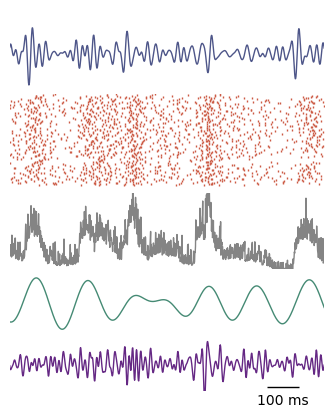

In [ ]:
# File Path

filepath = "./data/rand3hard1_out/"  #Hard
#filepath = "./data/rand3bio1_out/" #Bio

fs = 1000

# Read data
time_cx = np.loadtxt(filepath + "time_cx.gz")
#index = np.arange(10000, time_cx.shape[0]) #skip the first 10s
index = np.arange(10000+30000, 10000+30000+5000) 
time = (index - index[0]) / 1000 # seconds,start at 0
data = time_cx[index, 1:-1].T

# Read spike data
spdata = np.loadtxt(filepath+"spike_time")
end_time = np.max(spdata[:, 0])  # Python uses 0-based indexing
cxspdata = spdata[spdata[:, 1] == 4, :]
spikedata, min_time = reorganize_spiketime(cxspdata)
# This prepends zeros before the first spike time
zeros_to_prepend = np.zeros((spikedata.shape[0], int(min_time - 1)))
spikedata = np.hstack((zeros_to_prepend, spikedata))
M, N = spikedata.shape

# Find spike indices
neuron_indices, time_bins = np.where(spikedata == 1)   
# Convert time bins to actual time
bin_size=1
actual_times = min_time + time_bins * bin_size

# External current
from scipy.signal import decimate
bio_current = np.loadtxt(filepath + "bio_current.dat")
Iext = bio_current[index,1]

# Compute LFP
LFP = np.sum(data, axis=0) / data.shape[0]
LFP = detrend(LFP)

# bandpass filter
fLFP = filter_eeg_bandpass(LFP, fs, lowcut=0.5, highcut=90, order=4)
theta = filter_eeg_bandpass(LFP, fs, lowcut=4, highcut=8, order=4)
gamma = filter_eeg_bandpass(LFP, fs, lowcut=30, highcut=90, order=4)
freqs_tf, t_tf, tf_power = compute_standard_spectrogram(
    fLFP,fs=fs,epoch_sec=0.5,step_sec=0.001,   # smaller step -> smoother time axis
    fmin=0.5,fmax=60,log_scale=True
)

#mycolor = [np.array([62, 131, 192]) / 255, np.array([223, 96, 65]) / 255,
#           np.array([103, 139, 143]) / 255,
#           np.array([158, 129, 183]) / 255, np.array([95, 51, 49]) / 255,
#           np.array([234, 195, 107]) / 255]

mycolor = ['#4E5689','#CC5B45','#848484','#458A74','#652884']
#fig, axes = plt.subplots(5, 1, figsize=(4.5*0.8,5.5*0.85), gridspec_kw={'height_ratios':[1,1.8,1,1,1]})
fig, axes = plt.subplots(5, 1, figsize=(4.5*0.9,5.5*0.9), gridspec_kw={'height_ratios':[1,1.2,1,0.7, 0.7]})
plt.subplots_adjust(hspace=0.1, wspace=0.1)
# (1) Input current
axes[0].plot(time, Iext, color=mycolor[0], linewidth=1)
#axes[0].set_xlabel("Time (s)", fontsize=10)

axes[0].set_xlim([1, 2])
axes[0].set_xticklabels([])
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].set_ylim([-1.5,2.0])
#axes[0].axis('off')
hide_all_spines(axes[0])

# (2) Spike data
# Plot each spike as a point
# Define xlim boundaries
xlim_start = index[0] + min_time + 1000
xlim_end = index[0] + min_time + 2000

# Filter data before plotting
mask = (actual_times >= xlim_start) & (actual_times <= xlim_end)

# Plot only filtered data (not all data)
axes[1].scatter(actual_times[mask], neuron_indices[mask], 
                s=1, color=mycolor[1], marker='|', linewidths=1)

axes[1].set_ylim(-0.5, spikedata.shape[0] + 0.5)
axes[1].set_xlim(xlim_start, xlim_end)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].set_xticklabels([])
#axes[1].axis('off')
hide_all_spines(axes[1])

# (3) LFP
axes[2].plot(time, LFP, color=mycolor[2], linewidth=1)
#axes[2].set_xlabel("Time (s)", fontsize=10)

axes[2].set_xlim([1, 2])
axes[2].set_ylim([-2.0,2.8])
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)
axes[2].set_xticklabels([])
#axes[2].axis('off')
hide_all_spines(axes[2])

# (4) Theta
axes[3].plot(time, theta, color=mycolor[3], linewidth=1)
#axes[3].plot(time, gamma, 'r', linewidth=1)
#axes[3].set_xlabel("Time (s)", fontsize=10)

axes[3].set_xlim([1, 2])
axes[3].set_ylim([-1.1,1.1])
axes[3].spines['top'].set_visible(False)
axes[3].spines['right'].set_visible(False)
axes[3].set_xticklabels([])
hide_all_spines(axes[3])


# (5) Gamma
axes[4].plot(time, gamma, color=mycolor[4], linewidth=1)
#axes[4].set_xlabel("Time (s)", fontsize=10)

axes[4].set_xlim([1, 2])
axes[4].set_ylim([-0.7,0.7])
axes[4].spines['top'].set_visible(False)
axes[4].spines['right'].set_visible(False)
#axes[4].set_xticklabels([])
hide_all_spines(axes[4])


axes[4].hlines(y=-0.6, xmin=1.82, xmax=1.92, color='black', linewidth=1)
axes[4].text(1.87, -0.78, '100 ms', ha='center', va='top', fontsize=10, 
             transform=axes[4].transData, clip_on=False)
plt.show()


save_path_svg = r'./plot_ok_color.svg'
save_path_png = r'./plot_ok_color.png'

#  Set transparent=True to make the background transparent
fig.savefig(save_path_svg, bbox_inches='tight', dpi=300, transparent=True)
fig.savefig(save_path_png, bbox_inches='tight', dpi=300, transparent=True)